In [2]:
import pandas as pd

df = pd.read_csv('Desktop/Zindi projects/urban-air-pollution/Train.csv')
df.head()

,Place_ID X Date,Date,Place_ID,target,target_min,target_max,target_variance,target_count,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,...,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
0,010Q650 X 2020-01-02,2020-01-02,010Q650,38.0,23.0,53.0,769.50,92,11.000000,60.200001,...,38.593017,-61.752587,22.363665,1793.793579,3227.855469,0.010579,74.481049,37.501499,-62.142639,22.545118
1,010Q650 X 2020-01-03,2020-01-03,010Q650,39.0,25.0,63.0,1319.85,91,14.600000,48.799999,...,59.624912,-67.693509,28.614804,1789.960449,3384.226562,0.015104,75.630043,55.657486,-53.868134,19.293652
2,010Q650 X 2020-01-04,2020-01-04,010Q650,24.0,8.0,56.0,1181.96,96,16.400000,33.400002,...,49.839714,-78.342701,34.296977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,010Q650 X 2020-01-05,2020-01-05,010Q650,49.0,10.0,55.0,1113.67,96,6.911948,21.300001,...,29.181258,-73.896588,30.545446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,010Q650 X 2020-01-06,2020-01-06,010Q650,21.0,9.0,52.0,1164.82,95,13.900001,44.700001,...,0.797294,-68.612480,26.899694,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30557 entries, 0 to 30556
Data columns (total 82 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Place_ID X Date                                      30557 non-null  object 
 1   Date                                                 30557 non-null  object 
 2   Place_ID                                             30557 non-null  object 
 3   target                                               30557 non-null  float64
 4   target_min                                           30557 non-null  float64
 5   target_max                                           30557 non-null  float64
 6   target_variance                                      30557 non-null  float64
 7   target_count                                         30557 non-null  int64  
 8   precipitable_water_entire_atmosphere                 30557 non-nul

In [4]:
missing_percent = df.isnull().sum().sort_values(ascending=False) / len(df) * 100
missing_percent.head(20)

L3_CH4_solar_zenith_angle                              81.045260
L3_CH4_solar_azimuth_angle                             81.045260
L3_CH4_sensor_zenith_angle                             81.045260
L3_CH4_sensor_azimuth_angle                            81.045260
L3_CH4_aerosol_optical_depth                           81.045260
L3_CH4_aerosol_height                                  81.045260
L3_CH4_CH4_column_volume_mixing_ratio_dry_air          81.045260
L3_NO2_tropospheric_NO2_column_number_density          28.369932
L3_HCHO_tropospheric_HCHO_column_number_density_amf    24.298851
L3_HCHO_tropospheric_HCHO_column_number_density        24.298851
L3_HCHO_solar_zenith_angle                             24.298851
L3_HCHO_solar_azimuth_angle                            24.298851
L3_HCHO_sensor_zenith_angle                            24.298851
L3_HCHO_sensor_azimuth_angle                           24.298851
L3_HCHO_cloud_fraction                                 24.298851
L3_HCHO_HCHO_slant_column

In [5]:
df['target'].describe()

count    30557.000000
mean        61.148045
std         46.861309
min          1.000000
25%         25.000000
50%         50.000000
75%         80.000000
max        815.000000
Name: target, dtype: float64

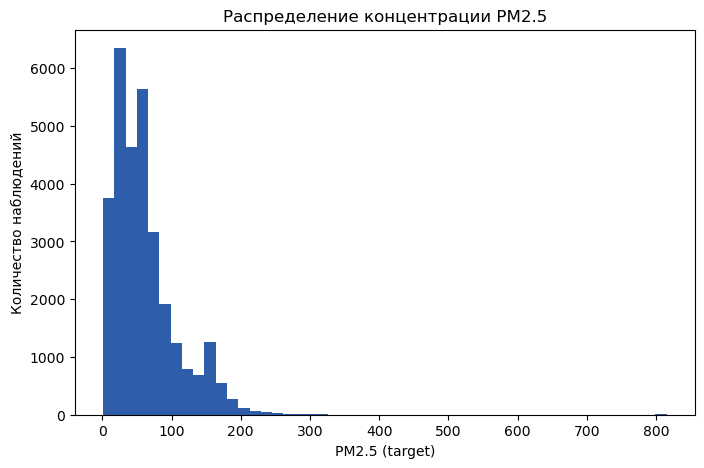

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df['target'], bins=50, color='#2E5EAA')
ax.set_xlabel('PM2.5 (target)')
ax.set_ylabel('Количество наблюдений')
ax.set_title('Распределение концентрации PM2.5')
plt.show()

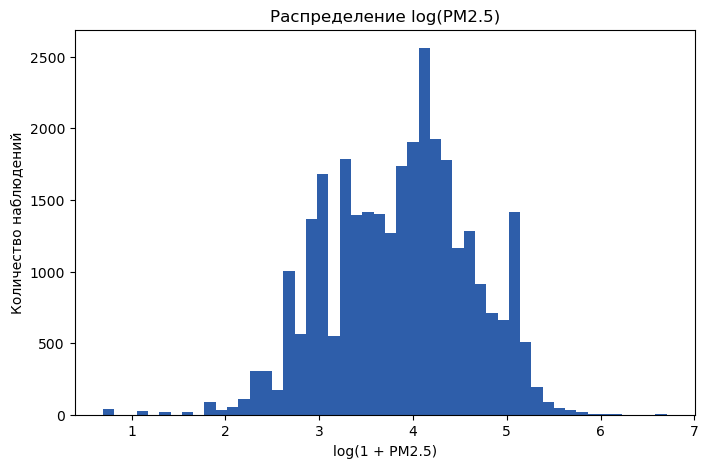

In [7]:
import numpy as np

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(np.log1p(df['target']), bins=50, color='#2E5EAA')
ax.set_xlabel('log(1 + PM2.5)')
ax.set_ylabel('Количество наблюдений')
ax.set_title('Распределение log(PM2.5)')
plt.show()

In [8]:
correlations = df.corr(numeric_only=True)['target'].sort_values(ascending=False)
correlations.head(15)

target                                             1.000000
target_min                                         0.818803
target_max                                         0.630801
L3_CO_CO_column_number_density                     0.375737
L3_HCHO_tropospheric_HCHO_column_number_density    0.347125
L3_HCHO_HCHO_slant_column_number_density           0.320849
L3_NO2_NO2_slant_column_number_density             0.315718
L3_NO2_NO2_column_number_density                   0.306772
L3_NO2_tropospheric_NO2_column_number_density      0.295380
target_variance                                    0.184818
L3_SO2_absorbing_aerosol_index                     0.152000
L3_CLOUD_cloud_top_pressure                        0.123855
L3_CLOUD_cloud_base_pressure                       0.097343
target_count                                       0.094135
L3_CH4_aerosol_optical_depth                       0.086445
Name: target, dtype: float64

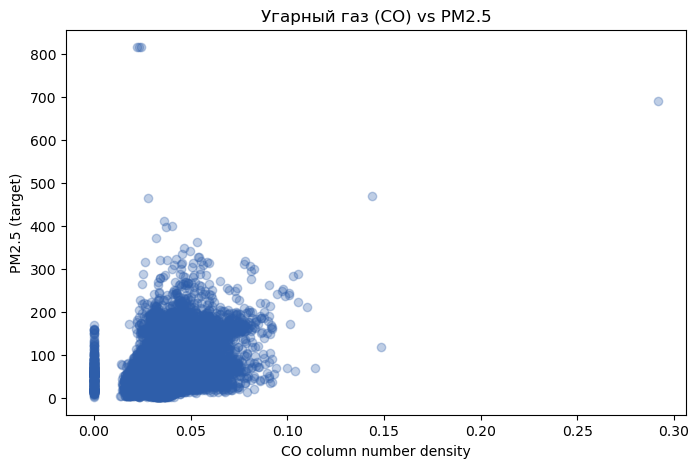

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df['L3_CO_CO_column_number_density'], df['target'], alpha=0.3, color='#2E5EAA')
ax.set_xlabel('CO column number density')
ax.set_ylabel('PM2.5 (target)')
ax.set_title('Угарный газ (CO) vs PM2.5')
plt.show()

In [10]:
df[df['target'] > 700]

,Place_ID X Date,Date,Place_ID,target,target_min,target_max,target_variance,target_count,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,...,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
4453,426FKUG X 2020-02-09,2020-02-09,426FKUG,815.0,82.0,815.0,1188380.0,40,8.471429,23.442857,...,8.056621,-157.709027,39.146939,1859.337138,2727.946435,0.033287,67.984756,7.997689,-157.649837,39.133057
4455,426FKUG X 2020-02-11,2020-02-11,426FKUG,815.0,61.0,815.0,1261770.0,41,15.014286,35.628573,...,58.396401,-171.728926,36.234062,1834.629935,2908.857049,0.014343,66.298831,58.435925,-171.606018,36.139873
4456,426FKUG X 2020-02-12,2020-02-12,426FKUG,815.0,2.0,815.0,1318070.0,46,12.528572,29.471429,...,57.442645,-142.722236,43.375964,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4465,426FKUG X 2020-02-21,2020-02-21,426FKUG,815.0,60.0,815.0,1363900.0,41,9.671429,15.171429,...,46.851716,-165.142246,33.428196,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df[df['Place_ID'] == '426FKUG']

,Place_ID X Date,Date,Place_ID,target,target_min,target_max,target_variance,target_count,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,...,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
4439,426FKUG X 2020-01-18,2020-01-18,426FKUG,1.0,1.0,1.0,0.00,2,20.528572,49.042858,...,16.123718,-155.790641,46.081086,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4440,426FKUG X 2020-01-19,2020-01-19,426FKUG,1.0,1.0,1.0,0.00,3,17.200001,35.557145,...,19.297004,-161.372080,44.263745,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4441,426FKUG X 2020-01-26,2020-01-26,426FKUG,1.0,1.0,1.0,0.00,3,19.665397,47.528573,...,58.411427,-172.100170,40.959742,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4442,426FKUG X 2020-01-29,2020-01-29,426FKUG,65.0,27.0,144.0,6370.16,36,6.042857,23.314286,...,4.278490,-157.064199,42.829228,1851.356619,3080.095689,0.112225,-88.973068,4.993259,-156.981025,42.889294
4443,426FKUG X 2020-01-30,2020-01-30,426FKUG,50.0,11.0,124.0,8291.90,48,10.757143,27.285714,...,30.681774,-163.458710,41.266254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4503,426FKUG X 2020-03-31,2020-03-31,426FKUG,60.0,28.0,151.0,8342.13,48,14.728572,18.985715,...,57.430440,-118.607342,32.088198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4504,426FKUG X 2020-04-01,2020-04-01,426FKUG,67.0,67.0,83.0,1280.00,2,20.628572,28.171429,...,37.049032,-123.605623,28.145890,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4505,426FKUG X 2020-04-02,2020-04-02,426FKUG,47.0,28.0,80.0,1433.60,48,18.170641,23.771429,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4506,426FKUG X 2020-04-03,2020-04-03,426FKUG,50.0,4.0,75.0,2118.61,48,13.571429,15.557143,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [12]:
exclude_cols = ['Place_ID X Date', 'Date', 'Place_ID', 'target', 'target_min', 'target_max', 'target_variance', 'target_count']
ch4_cols = [col for col in df.columns if col.startswith('L3_CH4')]

feature_cols = [col for col in df.columns if col not in exclude_cols and col not in ch4_cols]

print(len(feature_cols))
feature_cols

67


['precipitable_water_entire_atmosphere',
 'relative_humidity_2m_above_ground',
 'specific_humidity_2m_above_ground',
 'temperature_2m_above_ground',
 'u_component_of_wind_10m_above_ground',
 'v_component_of_wind_10m_above_ground',
 'L3_NO2_NO2_column_number_density',
 'L3_NO2_NO2_slant_column_number_density',
 'L3_NO2_absorbing_aerosol_index',
 'L3_NO2_cloud_fraction',
 'L3_NO2_sensor_altitude',
 'L3_NO2_sensor_azimuth_angle',
 'L3_NO2_sensor_zenith_angle',
 'L3_NO2_solar_azimuth_angle',
 'L3_NO2_solar_zenith_angle',
 'L3_NO2_stratospheric_NO2_column_number_density',
 'L3_NO2_tropopause_pressure',
 'L3_NO2_tropospheric_NO2_column_number_density',
 'L3_O3_O3_column_number_density',
 'L3_O3_O3_effective_temperature',
 'L3_O3_cloud_fraction',
 'L3_O3_sensor_azimuth_angle',
 'L3_O3_sensor_zenith_angle',
 'L3_O3_solar_azimuth_angle',
 'L3_O3_solar_zenith_angle',
 'L3_CO_CO_column_number_density',
 'L3_CO_H2O_column_number_density',
 'L3_CO_cloud_height',
 'L3_CO_sensor_altitude',
 'L3_CO_se

In [13]:
X = df[feature_cols]
y = df['target']

X = X.fillna(X.median())

print(X.isnull().sum().sum())

0


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

val_preds = model.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, val_preds))
print("RMSE:", rmse)

RMSE: 37.4162469485795


In [15]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_val_preds = rf_model.predict(X_val)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_val_preds))
print("RMSE (Random Forest):", rf_rmse)

RMSE (Random Forest): 30.36450361300082


In [18]:
test = pd.read_csv('Desktop/Zindi projects/urban-air-pollution/Test.csv')
sample_sub = pd.read_csv('Desktop/Zindi projects/urban-air-pollution/SampleSubmission.csv')

X_test = test[feature_cols]
X_test = X_test.fillna(X.median())

print(X_test.isnull().sum().sum())
sample_sub.head()

0


,Place_ID X Date,target
0,0OS9LVX X 2020-01-02,0
1,0OS9LVX X 2020-01-03,0
2,0OS9LVX X 2020-01-04,0
3,0OS9LVX X 2020-01-05,0
4,0OS9LVX X 2020-01-06,0


In [19]:
test_preds = rf_model.predict(X_test)

submission = pd.DataFrame({
    'Place_ID X Date': test['Place_ID X Date'],
    'target': test_preds
})

submission.to_csv('submission.csv', index=False)
submission.head()

,Place_ID X Date,target
0,0OS9LVX X 2020-01-02,45.352
1,0OS9LVX X 2020-01-03,37.618
2,0OS9LVX X 2020-01-04,36.209
3,0OS9LVX X 2020-01-05,36.165
4,0OS9LVX X 2020-01-06,43.783
